In [2]:
import pandas as pd
import os
import matplotlib.pyplot as plt
import string

In [ ]:
def plot_individual_graphs(df, metrics, color_dict, label_dict, output_path, output_desc):
    for metric in metrics:
        fig = plt.figure(figsize = (6,5), facecolor = 'w', edgecolor = 'k')
        plt.grid(color = 'k', ls = '-.', lw = 0.1, alpha = 0.5)
        plt.xticks(fontsize = 16)
        plt.yticks(fontsize = 16)
        plt.plot(df['Trees'], df[metric], linewidth = 3, color = color_dict.get(metric, 'black'))
        plt.xlabel('Number of Trees', fontsize = 18)
        plt.ylabel(label_dict.get(metric, metric), fontsize = 18)
        metric_name = metric.lower().replace('/','_')
        plt.tight_layout()
        plt.savefig(os.path.join(output_path, f'rf_opt_{metric_name}_vs_trees_rotated_{output_desc}.pdf'))
        #plt.savefig(os.path.join(output_path, f'rf_opt_{metric_name}_vs_trees_rotated.png'), dpi = 300)

In [4]:
def plot_grid_graph(df, metrics, color_dict, label_dict, output_path, output_desc):
    fig, axes = plt.subplots(2, 2, figsize = (12, 10))
    axes = axes.flatten()

    for i, (ax, metric) in enumerate(zip(axes, metrics)):
        ax.grid(color = 'lightgrey', ls = '-.', lw = 0.1)
        ax.plot(df['Trees'], df[metric], linewidth = 3, color = color_dict.get(metric, 'black'))
        ax.set_xlabel('Number of Trees', fontsize = 24)
        ax.set_ylabel(label_dict.get(metric, metric), fontsize = 24)
        ax.tick_params(axis = 'both', which = 'major', labelsize = 16)
        ax.text(-0.1, 1.05, f"{string.ascii_uppercase[i]})", transform = ax.transAxes, size = 20)

    plt.tight_layout()
    plt.savefig(os.path.join(output_path, f'rf_opt_graphs_combined_rotated_{output_desc}.pdf'))
    #plt.savefig(os.path.join(output_path, f'rf_opt_graphs_combined_rotated.png'), dpi = 300)

In [ ]:
def plot_all_graphs(input_file, metrics, color_dict, label_dict, output_desc):
    output_path = os.path.join(os.getcwd(), 'output')
    df = pd.read_csv(input_file)

    df['Score/Runtime'] = df['Score'] / df['Runtime']

    plot_individual_graphs(df, metrics, color_dict, label_dict, output_path, output_desc)
    plot_grid_graph(df, metrics, color_dict, label_dict, output_path, output_desc)

In [ ]:
metrics = ['Score', 'Runtime', 'Score/Runtime', 'TotalRMSE']

color_dict = {
    'Score': '#648FFF',
    'Runtime': '#785EF0',
    'Score/Runtime': '#DC267F',
    'TotalRMSE': '#FE6100'
}

label_dict = {
    'Score': 'Score',
    'Runtime': 'Runtime (s)',
    'Score/Runtime': 'Score/Runtime (s$^{-1}$)',
    'TotalRMSE': 'RMSE (a.u.)'
}

input_output_dict = {
    'nnyzx': 'new-new-y-zx_42.csv',
    'noyzx': 'new-old-y-zx_42.csv',
    'ooyzx': 'old-old-y-zx_42.csv',
    'ooyaa': 'old-old-y-aa_42.csv',
}

inputs = list(input_output_dict.keys())

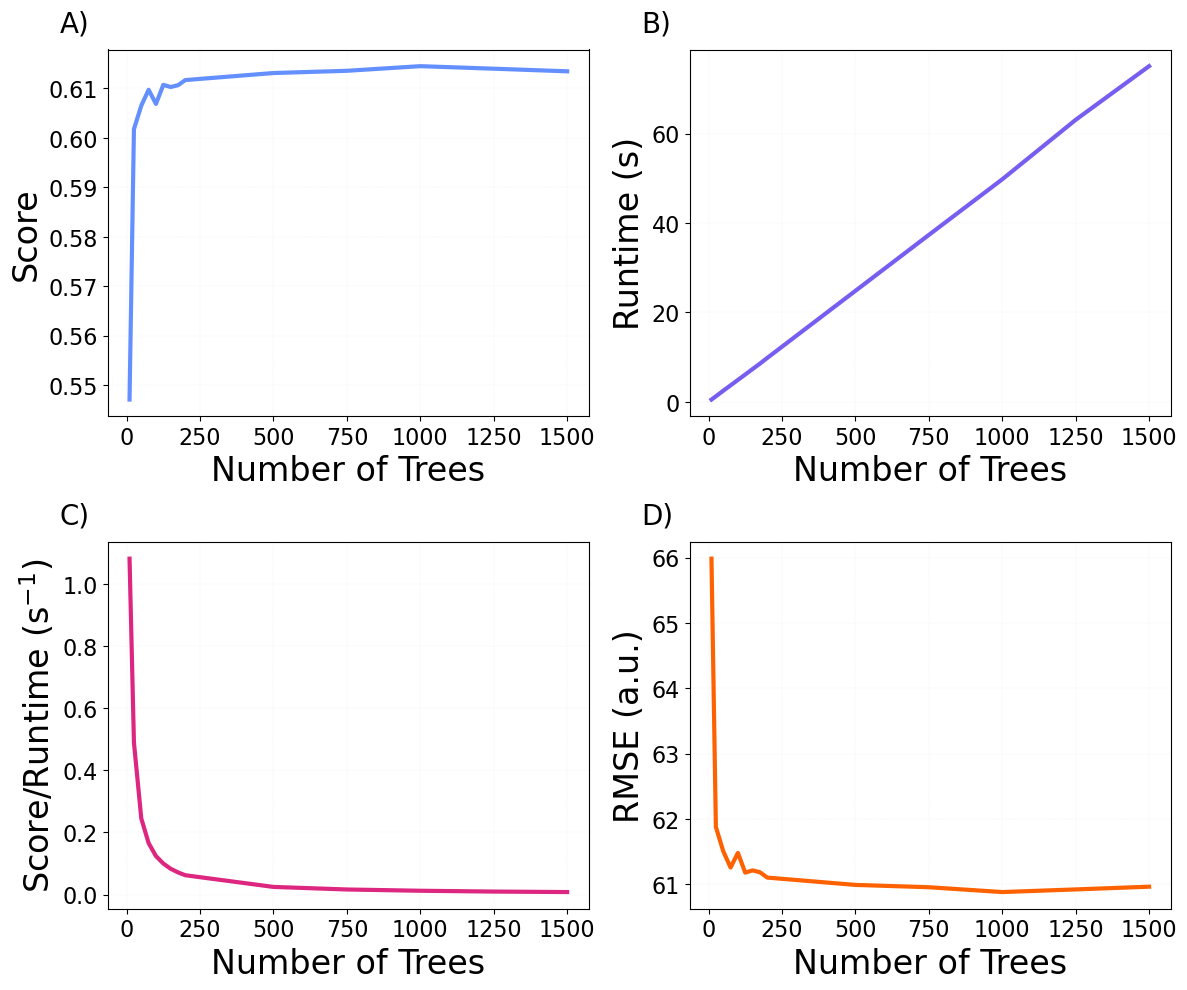

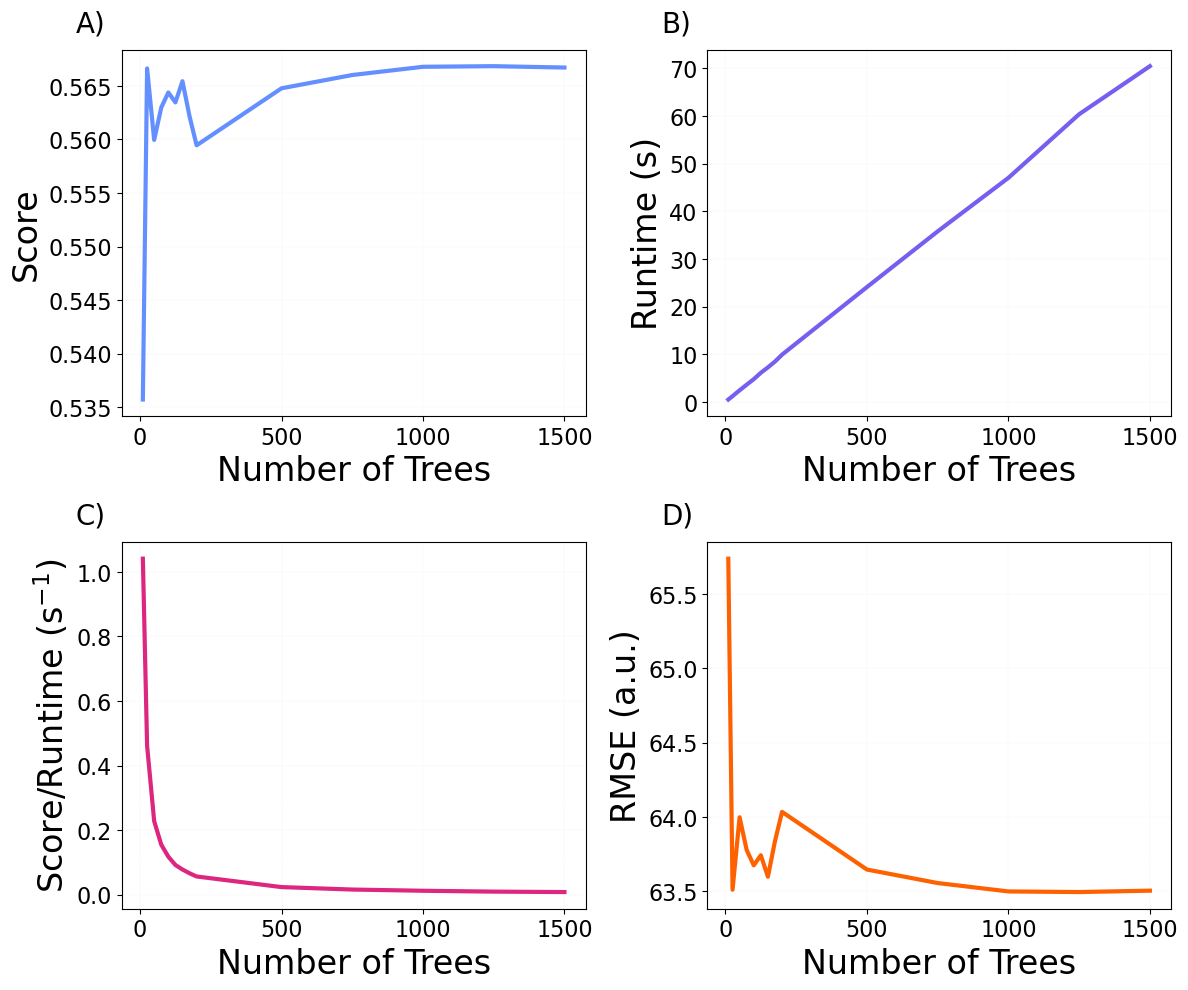

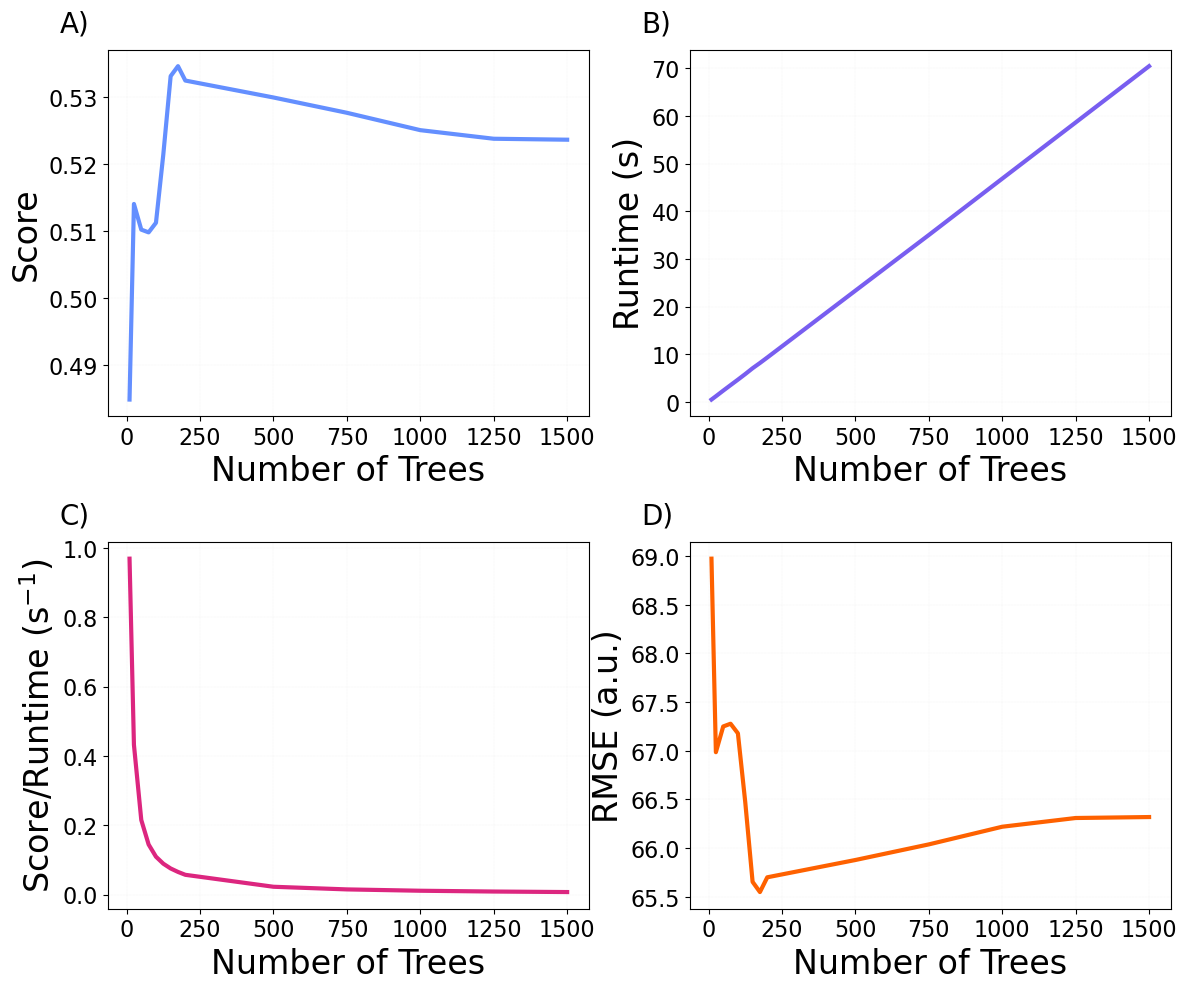

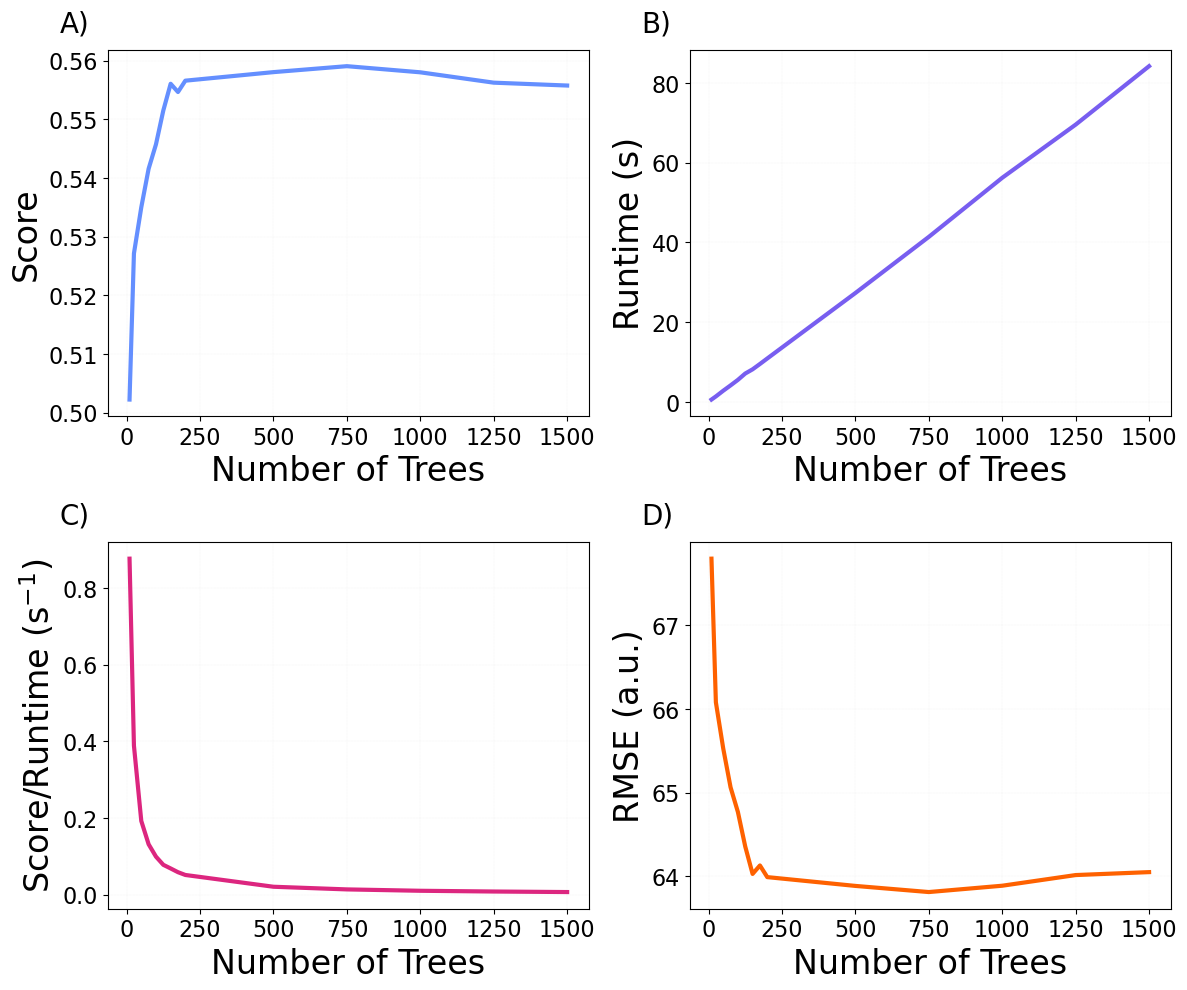

In [ ]:

for inp in inputs:
    input_file = input_output_dict.get(inp)
    plot_all_graphs(input_file, metrics, color_dict, label_dict, inp)